## Library reference for these exercises

Python syntax/classes and ML theory are assumed. Complete the corresponding lesson's library/API introductions before these independent exercises. The explanations focus on package behavior, method arguments, dtype/shape/device contracts, and the training workflow. Your existing answers are preserved.

Tensor/device API introductions are in Chapter 00; torch.manual_seed seeds available PyTorch devices. On your Mac, select MPS or CPU rather than CUDA.

<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/01_pytorch_workflow_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. PyTorch Workflow Exercise Template

The following is a template for the PyTorch workflow exercises.

It's only starter code and it's your job to fill in the blanks.

Because of the flexibility of PyTorch, there may be more than one way to answer the question.

Don't worry about trying to be *right* just try writing code that suffices the question.

You can see one form of [solutions on GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions) (but try the exercises below yourself first!).

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

## 1. Create a straight line dataset using the linear regression formula (`weight * X + bias`).
  * Set `weight=0.3` and `bias=0.9` there should be at least 100 datapoints total. 
  * Split the data into 80% training, 20% testing.
  * Plot the training and testing data so it becomes visual.

Your output of the below cell should look something like:
```
Number of X samples: 100
Number of y samples: 100
First 10 X & y samples:
X: tensor([0.0000, 0.0100, 0.0200, 0.0300, 0.0400, 0.0500, 0.0600, 0.0700, 0.0800,
        0.0900])
y: tensor([0.9000, 0.9030, 0.9060, 0.9090, 0.9120, 0.9150, 0.9180, 0.9210, 0.9240,
        0.9270])
```

Of course the numbers in `X` and `y` may be different but ideally they're created using the linear regression formula.

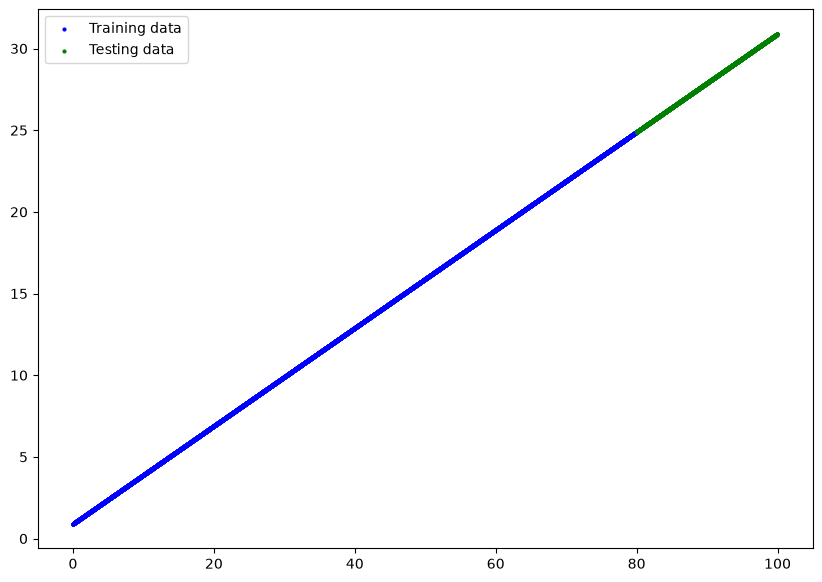

In [19]:
X = torch.arange(start=0, end=100, step=0.01, dtype=torch.float32).reshape(10000, 1)
y = 0.3 * X + 0.9

def plot_predictions(train_data, train_labels, test_data, test_labels, predictions=None):
    plt.figure(figsize=(10, 7))
    plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")
    plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")
    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")
    plt.legend()

train_data = X[:8000]
train_labels = y[:8000]
test_data = X[8000:10000]
test_labels = y[8000:10000]

plot_predictions(train_data, train_labels, test_data, test_labels)


## 2. Build a PyTorch model by subclassing `nn.Module`. 
  * Inside should be a randomly initialized `nn.Parameter()` with `requires_grad=True`, one for `weights` and one for `bias`. 
  * Implement the `forward()` method to compute the linear regression function you used to create the dataset in 1. 
  * Once you've constructed the model, make an instance of it and check its `state_dict()`.
  * **Note:** If you'd like to use `nn.Linear()` instead of `nn.Parameter()` you can.

In [5]:
class LinearrRegressionModelExercise(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(1, dtype=torch.float32), requires_grad = True)
        self.bias = nn.Parameter(torch.randn(1, dtype=torch.float32), requires_grad = True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weights * x + self.bias

In [8]:
model = LinearrRegressionModelExercise()

## 3. Create a loss function and optimizer using `nn.L1Loss()` and `torch.optim.SGD(params, lr)` respectively. 
  * Set the learning rate of the optimizer to be 0.01 and the parameters to optimize should be the model parameters from the model you created in 2.
  * Write a training loop to perform the appropriate training steps for 300 epochs.
  * The training loop should test the model on the test dataset every 20 epochs.

In [20]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.001)

In [21]:
epochs = 300
epoch_count = []
loss_values = []

for epoch in range(epochs):
    if epoch % 20 == 0:
        model.eval()
        with torch.inference_mode():
            y_pred = model(test_data)
            test_loss = loss_fn(y_pred, test_labels)
            print(f"Epoch: {epoch} | Test loss: {test_loss:.4f}")

    model.train()
    optimizer.zero_grad()
    y_pred = model(train_data)
    
    training_loss = loss_fn(y_pred, train_labels)
    loss_values.append(training_loss.item())
    training_loss.backward()
    
    optimizer.step()
    

Epoch: 0 | Test loss: 14.0065
Epoch: 20 | Test loss: 1.2430
Epoch: 40 | Test loss: 1.4470
Epoch: 60 | Test loss: 1.0507
Epoch: 80 | Test loss: 2.2893
Epoch: 100 | Test loss: 3.5956
Epoch: 120 | Test loss: 1.1443
Epoch: 140 | Test loss: 3.5885
Epoch: 160 | Test loss: 2.8837
Epoch: 180 | Test loss: 3.5909
Epoch: 200 | Test loss: 0.7000
Epoch: 220 | Test loss: 0.3203
Epoch: 240 | Test loss: 0.8170
Epoch: 260 | Test loss: 0.0799
Epoch: 280 | Test loss: 0.7848


## 4. Make predictions with the trained model on the test data.
  * Visualize these predictions against the original training and testing data (**note:** you may need to make sure the predictions are *not* on the GPU if you want to use non-CUDA-enabled libraries such as matplotlib to plot).

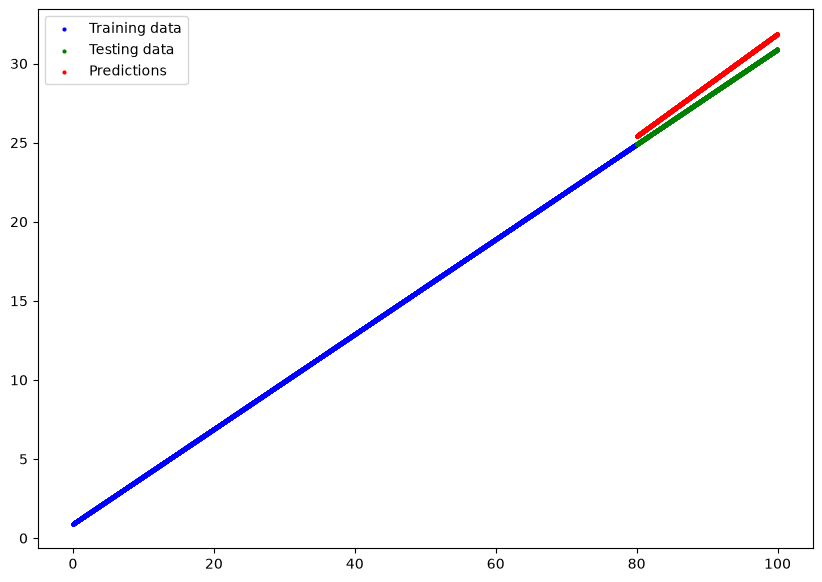

In [22]:
plot_predictions(train_data, train_labels, test_data, test_labels, model(test_data).detach())

## 5. Save your trained model's `state_dict()` to file.
  * Create a new instance of your model class you made in 2. and load in the `state_dict()` you just saved to it.
  * Perform predictions on your test data with the loaded model and confirm they match the original model predictions from 4.

In [24]:
from pathlib import Path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_SAVE_PATH = MODEL_PATH / "00_pytorch_fundamentals_exercises.pth"
torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)